# 01 · Ingesta, calidad y armonización de categorías

El portal de Chicago publica *Crimes – 2001 to Present* (`ijzp-q8t2`). `descargar_datos.py` baja un CSV por año y `ingesta.py` los convierte con DuckDB en Parquet particionado por año. Este notebook revisa:

1. La **trazabilidad** de los archivos fuente (URL, fecha, filas y SHA-256).
2. La **auditoría de calidad** de la ingesta (duplicados, fechas, coordenadas).
3. La **armonización de categorías**: un tipo de delito cambió de nombre y, si no se corrige, aparece como un salto falso.

La ingesta completa (2,4 GB de CSV) no se repite aquí: se leen sus resultados en `reports/calidad.json`.

In [1]:
import json
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from delitos_chicago.config import FIGURAS, PROCESADOS, REPORTES
import delitos_chicago.pipeline  # los módulos fijan el backend Agg al importarse; después se activa el inline
%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

## 1. Manifiesto de la fuente

In [2]:
manifiesto = json.loads((PROCESADOS.parent / "manifiesto_fuente.json").read_text(encoding="utf-8"))
archivos = pd.DataFrame(manifiesto["archivos"])
archivos["sha256"] = archivos["sha256"].str[:16] + "…"
print(f"Consulta a la API: {manifiesto['consultado_utc']} · conteo oficial {manifiesto['conteo_api']:,}")
print(f"Filas en los CSV descargados: {archivos['filas'].sum():,.0f}")
archivos[["archivo", "fecha_descarga_utc", "filas", "bytes", "sha256"]]

Consulta a la API: 2026-10-24T12:34:03.545890+00:00 · conteo oficial 8,665,676
Filas en los CSV descargados: 8,665,676


,archivo,fecha_descarga_utc,filas,bytes,sha256
0,data/raw/crimes_2001.csv,2026-10-24T13:09:47+00:00,485979.0,132933095,7631b52ea90197cb…
1,data/raw/crimes_2002.csv,2026-10-24T13:07:57+00:00,486843.0,135999680,ab13dee69a798c57…
2,data/raw/crimes_2003.csv,2026-10-24T13:04:19+00:00,476013.0,135454075,2d73d65314045ff9…
3,data/raw/crimes_2004.csv,2026-10-24T13:02:48+00:00,469447.0,133824711,8533ba78809d03b3…
4,data/raw/crimes_2005.csv,2026-10-24T13:01:56+00:00,453803.0,129377419,83e108ddefbeab51…
5,data/raw/crimes_2006.csv,2026-10-24T13:00:58+00:00,448211.0,127887803,801f37bf230cc40d…
6,data/raw/crimes_2007.csv,2026-10-24T12:59:07+00:00,437117.0,124714147,0ae459d33ab85d35…
7,data/raw/crimes_2008.csv,2026-10-24T12:57:24+00:00,427231.0,121381797,61ea040aacffdf5d…
8,data/raw/crimes_2009.csv,2026-10-24T12:55:26+00:00,392879.0,111735148,1ad9c2611c20bf69…
9,data/raw/crimes_2010.csv,2026-10-24T12:53:42+00:00,370590.0,105922652,63d947bc02956266…


Las filas de los 26 CSV suman exactamente el conteo que devolvió la API el día de la descarga.

## 2. Auditoría de calidad de la ingesta

In [3]:
calidad = json.loads((REPORTES / "calidad.json").read_text(encoding="utf-8"))
pd.Series({k: v for k, v in calidad.items() if k != "distribucion_anios"}, name="valor").to_frame()

,valor
archivos_evaluados,26.00
total_registros_brutos,8665676.00
duplicados_id,0.00
fechas_invalidas,0.00
sin_coordenadas,100954.00
pct_sin_coordenadas,1.16
coordenadas_fuera_chicago,149.00
total_registros_limpios,8665676.00
pct_retenido,100.00


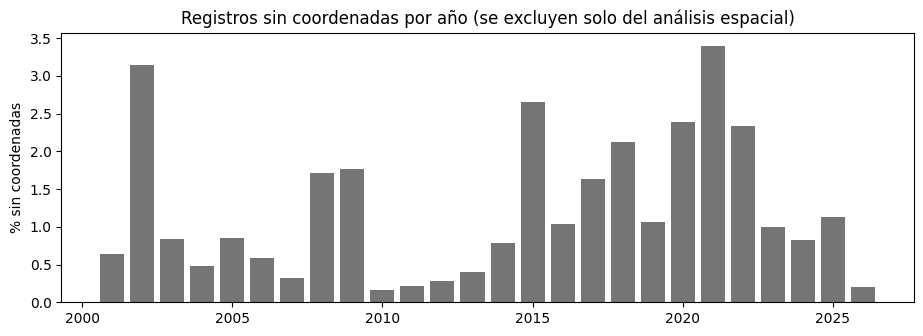

In [4]:
import duckdb
patron = (PROCESADOS / "delitos_parquet" / "**" / "*.parquet").as_posix()
por_anio = duckdb.sql(f"""
    SELECT CAST(anio AS INTEGER) AS anio, count(*) AS delitos,
           avg(CASE WHEN latitud IS NULL THEN 1 ELSE 0 END) * 100 AS pct_sin_coordenadas
    FROM read_parquet('{patron}', hive_partitioning=true) GROUP BY 1 ORDER BY 1""").df()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(por_anio["anio"], por_anio["pct_sin_coordenadas"], color="#757575")
ax.set_ylabel("% sin coordenadas")
ax.set_title("Registros sin coordenadas por año (se excluyen solo del análisis espacial)")
plt.show()

Los registros sin coordenadas se concentran en los primeros años. No se borran: entran al análisis temporal y policial y solo se excluyen del espacial.

## 3. Armonización de categorías

`armonizacion.detectar_renombres` busca las categorías que dejan de aparecer y comprueba si sus códigos IUCR (que no dependen de la etiqueta) se siguen registrando después bajo otra categoría.

In [5]:
from delitos_chicago.armonizacion import comparar_antes_despues, detectar_renombres, mapa_renombres
conteos = duckdb.sql(f"""
    SELECT CAST(anio AS INTEGER) AS anio, tipo_primario, codigo_iucr, count(*) AS conteo
    FROM read_parquet('{patron}', hive_partitioning=true) GROUP BY ALL""").df()
tabla = detectar_renombres(conteos, anio_ultimo=int(conteos["anio"].max()) - 1)
tabla

,tipo_original,tipo_armonizado,primer_anio_original,ultimo_anio_original,registros_original,codigos_iucr,cobertura_iucr_pct,decision
0,CRIM SEXUAL ASSAULT,CRIMINAL SEXUAL ASSAULT,2001,2020,27237,13,100.0,renombre: se armoniza
2,RITUALISM,RITUALISM,2001,2020,24,5,0.0,sin sucesor: sus códigos IUCR no vuelven a apa...
1,DOMESTIC VIOLENCE,DOMESTIC VIOLENCE,2001,2001,1,1,0.0,sin sucesor: sus códigos IUCR no vuelven a apa...


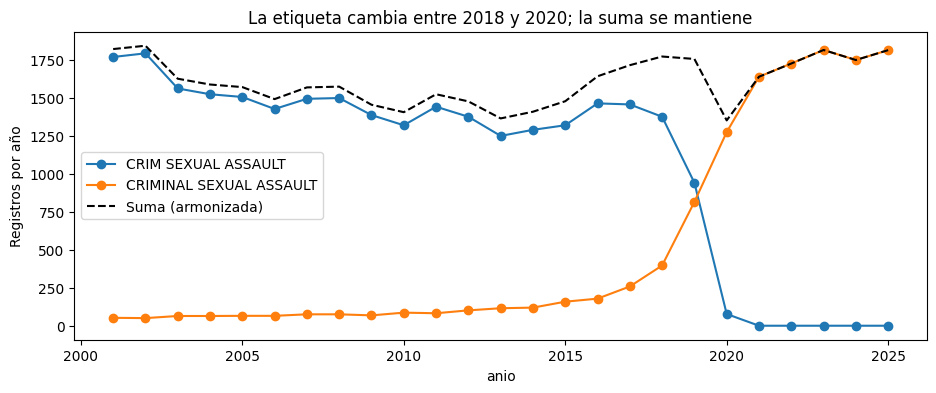

In [6]:
serie = (conteos[conteos["tipo_primario"].isin(["CRIM SEXUAL ASSAULT", "CRIMINAL SEXUAL ASSAULT"])]
         .groupby(["anio", "tipo_primario"])["conteo"].sum().unstack(fill_value=0))
serie = serie[serie.index <= 2025]
fig, ax = plt.subplots(figsize=(11, 4))
serie.plot(ax=ax, marker="o")
ax.plot(serie.index, serie.sum(axis=1), color="black", linestyle="--", label="Suma (armonizada)")
ax.set_ylabel("Registros por año")
ax.set_title("La etiqueta cambia entre 2018 y 2020; la suma se mantiene")
ax.legend()
plt.show()

In [7]:
comparar_antes_despues(conteos, mapa_renombres(tabla), 2019, 2024)

,categoria,grupo,conteo_2019,conteo_2024,cambio_pct
0,CRIM SEXUAL ASSAULT,CRIMINAL SEXUAL ASSAULT,940,0,-100.0
1,CRIMINAL SEXUAL ASSAULT,CRIMINAL SEXUAL ASSAULT,814,1747,114.6
2,CRIMINAL SEXUAL ASSAULT (armonizada),CRIMINAL SEXUAL ASSAULT,1754,1747,-0.4


Sin armonizar, `CRIMINAL SEXUAL ASSAULT` parece subir más del 100 % entre 2019 y 2024; con las dos etiquetas sumadas el cambio es prácticamente nulo. El pipeline aplica el mapa de renombres en la propia consulta de DuckDB, así que todo el análisis (tendencias, cambios por tipo, arrestos, app) usa las categorías armonizadas.